<figure>
<center>
<img src='https://www.economicas.uba.ar/wp-content/uploads/2020/08/cropped-logo_FCE.png' />
</figure>

# APIs Financieras con Python

Una **API** (Application Programming Interface) permite que dos programas se comuniquen a través de la red.  
En finanzas, las APIs son la forma estándar de acceder a precios de activos, tipos de cambio e indicadores macroeconómicos — sin descargar archivos manualmente ni scrappear páginas web.

En esta notebook trabajamos con tres fuentes de datos:

| Fuente | Acceso | Qué provee |
|---|---|---|
| **Yahoo Finance** | Librería `yfinance` | Precios históricos de acciones, ETFs, criptomonedas y ADRs |
| **API Dólar** | `requests` (REST) | Tipos de cambio en Argentina en tiempo real |
| **Argentina Datos** | `requests` (REST) | Inflación mensual, IPC y otros indicadores del INDEC |

---

**Dos modalidades de consumo de APIs:**

- **Librería dedicada** (`yfinance`): alguien ya construyó el cliente HTTP por nosotros; llamamos funciones Python y recibimos DataFrames directamente.  
- **REST directo** (`requests`): construimos el request HTTP manualmente, recibimos JSON, y lo convertimos a DataFrame. Este es el caso general — la gran mayoría de APIs públicas funciona así.

In [1]:
import sys
!{sys.executable} -m pip install yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 12.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 13.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [yfinance]/11 [yfinance]]


In [2]:
import yfinance as yf
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


---
## 1. Yahoo Finance con `yfinance`

`yfinance` es una librería que envuelve la API no oficial de Yahoo Finance.  
En lugar de construir requests HTTP manualmente, llamamos funciones Python y recibimos DataFrames.

Cada activo se identifica con un **ticker** — el código bursátil único:

| Ticker | Activo |
|--------|--------|
| `AAPL` | Apple Inc. |
| `MSFT` | Microsoft |
| `GGAL` | Grupo Financiero Galicia (ADR en NYSE) |
| `BTC-USD` | Bitcoin en dólares |

> **ADR** (American Depositary Receipt): certificado que representa acciones de una empresa extranjera y cotiza en bolsas americanas como NYSE o NASDAQ.

### 1.1 Precio histórico — `yf.download()`

`yf.download()` devuelve un DataFrame con columnas:  
`Open`, `High`, `Low`, `Close` (precios en USD) y `Volume` (unidades negociadas).

Con `auto_adjust=True` los precios ya incorporan dividendos y splits — es la versión correcta para análisis.

In [3]:
FECHA_DESDE = '2025-01-01'
FECHA_HASTA = '2026-01-01'

aapl = yf.download('AAPL', start=FECHA_DESDE, end=FECHA_HASTA, auto_adjust=True, progress=False)

# Con un solo ticker, aplanamos el MultiIndex de columnas
aapl.columns = aapl.columns.get_level_values(0)

print(f"Período:  {aapl.index[0].date()} → {aapl.index[-1].date()}")
print(f"Filas:    {len(aapl)}")
print(f"Columnas: {list(aapl.columns)}")

Período:  2025-01-02 → 2025-12-31
Filas:    250
Columnas: ['Close', 'High', 'Low', 'Open', 'Volume']


In [6]:
aapl.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2025-01-02,242.093124,247.305299,240.077751,247.136511,55740700
2025-01-03,241.606659,242.420743,240.147249,241.606659,40244100
2025-01-06,243.234863,245.548078,241.447829,242.549832,45045600
2025-01-07,240.464935,243.780868,239.611131,241.229377,40856000
2025-01-08,240.951401,241.954134,238.320499,240.177022,37628900


In [7]:
# Estadísticas descriptivas del precio de cierre
aapl['Close'].describe() #.round(2)

count    250.000000
mean     231.150535
std       26.552091
min      171.365967
25%      209.002380
50%      229.028976
75%      253.396461
max      285.413116
Name: Close, dtype: float64

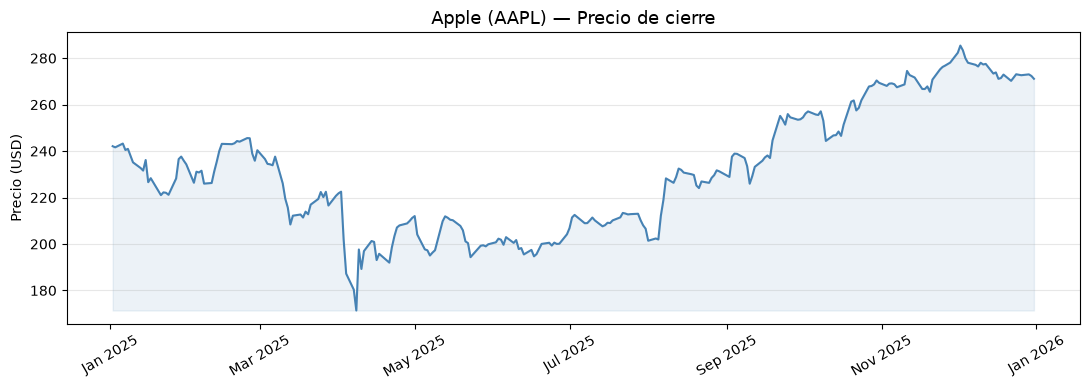

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(aapl.index, aapl['Close'], color='steelblue', linewidth=1.5)
ax.fill_between(aapl.index, aapl['Close'], aapl['Close'].min(), alpha=0.1, color='steelblue')

ax.set_title('Apple (AAPL) — Precio de cierre', fontsize=13)
ax.set_ylabel('Precio (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 1.2 Metadatos de la empresa — `Ticker.info`

El objeto `Ticker` tiene metadatos: sector, industria, market cap, P/E ratio, etc.  

In [13]:
ticker = yf.Ticker('AAPL')
info   = ticker.info

campos = {
    'longName':       'Nombre',
    'sector':         'Sector',
    'industry':       'Industria',
    'country':        'País'
}

for campo, etiqueta in campos.items():
    valor = info.get(campo, 'N/A')

    print(f"  {etiqueta:<16} {valor}")

  Nombre           Apple Inc.
  Sector           Technology
  Industria        Consumer Electronics
  País             United States


### 1.3 Comparación de activos — retorno relativo

Cuando dos activos tienen precios muy distintos (ej. AAPL a $200 vs MSFT a $400),
graficarlos directamente en el mismo eje no tiene sentido.

Una solución es **normalizar**: dividir cada serie por su valor inicial.  
Ambas arrancan en 1 y el gráfico muestra el retorno acumulado desde el inicio del período.

$$r_t = \frac{P_t}{P_0}$$

Un valor de 1.20 significa que el activo subió 20% desde el inicio.

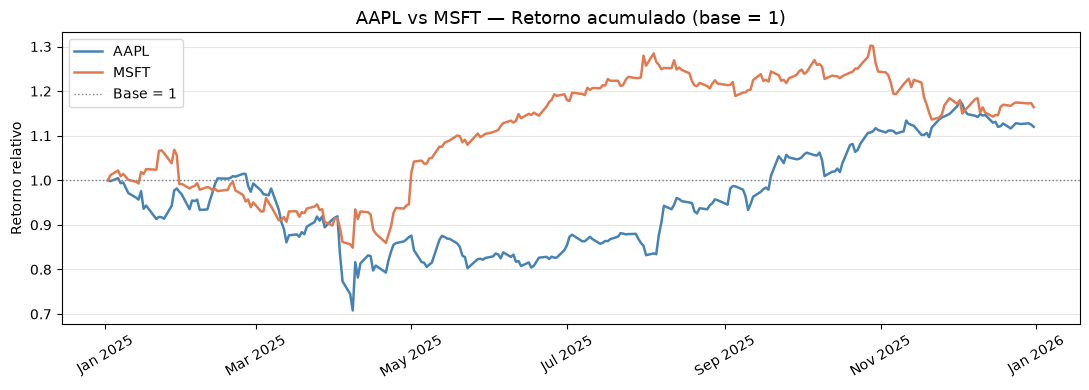


Retorno total del período:
  AAPL: +12.0%
  MSFT: +16.4%


In [14]:
tickers = ['AAPL', 'MSFT']
df_tickers = yf.download(tickers, start=FECHA_DESDE, end=FECHA_HASTA, auto_adjust=True, progress=False)

precios = df_tickers['Close']

# Normalizar: retorno acumulado desde el inicio del período
normalizado = precios / precios.iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))

colores = {'AAPL': 'steelblue', 'MSFT': '#e07a50'}
for col in normalizado.columns:
    ax.plot(normalizado.index, normalizado[col], label=col, linewidth=1.8, color=colores.get(col, 'gray'))

ax.axhline(1, color='gray', linestyle=':', linewidth=1, label='Base = 1')
ax.set_title('AAPL vs MSFT — Retorno acumulado (base = 1)', fontsize=13)
ax.set_ylabel('Retorno relativo')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30)
ax.grid(axis='y', alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# Resumen final
print("\nRetorno total del período:")
for col in normalizado.columns:
    ret = (normalizado[col].iloc[-1] - 1) * 100
    print(f"  {col}: {ret:+.1f}%")

### 1.4 ADRs argentinos en NYSE

Las principales empresas argentinas cotizan en la Bolsa de Nueva York como **ADRs**.  
`yfinance` las soporta con los mismos tickers:

| Ticker | Empresa |
|--------|---------|
| `GGAL` | Grupo Financiero Galicia |
| `BMA`  | Banco Macro |
| `YPF`  | YPF (petróleo y gas) |
| `PAM`  | Pampa Energía |

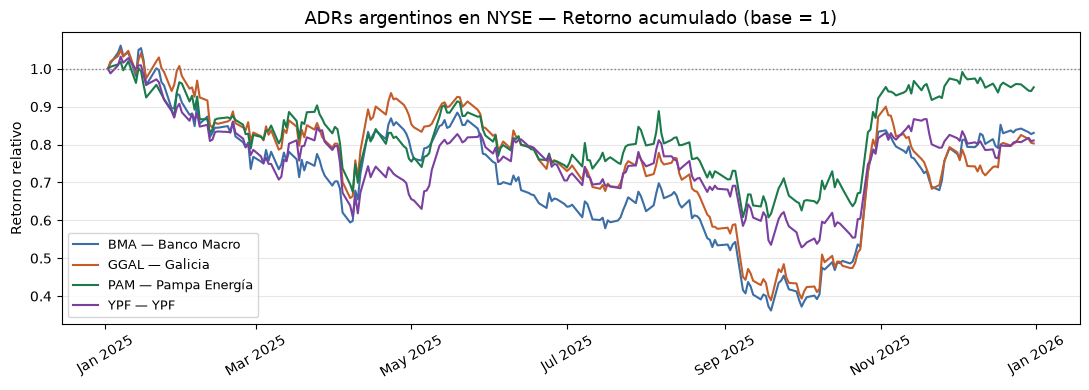


Retorno total del período:
  PAM (Pampa Energía   ): -4.9%
  BMA (Banco Macro     ): -16.9%
  YPF (YPF             ): -18.9%
  GGAL (Galicia         ): -19.7%


In [ ]:
argentinos = {
    'GGAL': 'Galicia',
    'BMA':  'Banco Macro',
    'YPF':  'YPF',
    'PAM':  'Pampa Energía',
}

df_arg = yf.download(  list(argentinos.keys()),  start=FECHA_DESDE, end=FECHA_HASTA,  auto_adjust=True, progress=False)

df_arg_precios=df_arg['Close']


# Normalizar para comparación en la misma escala
df_norm = df_arg_precios / df_arg_precios.iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))

palette = ['#3a6ea5', '#c45c2a', '#1a7a4a', '#7b3fa0']

for col, color in zip(df_norm.columns, palette):
    ax.plot(df_norm.index, df_norm[col],
            label=f'{col} — {argentinos.get(col, col)}',
            linewidth=1.5, color=color)

ax.axhline(1, color='gray', linestyle=':', linewidth=1)
ax.set_title('ADRs argentinos en NYSE — Retorno acumulado (base = 1)', fontsize=13)
ax.set_ylabel('Retorno relativo')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30)
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Ranking de retorno
print("\nRetorno total del período:")
retornos = ((df_norm.iloc[-1] - 1) * 100).sort_values(ascending=False)
for ticker, ret in retornos.items():
    print(f"  {ticker} ({argentinos.get(ticker, ticker):<16}): {ret:+.1f}%")

---
## 2. API Dólar — ccon `requests`

No todas las APIs tienen librería dedicada. La gran mayoría expone **endpoints**:
URLs a las que hacemos un request HTTP y recibimos una respuesta.

```
Cliente (Python)  ──── GET /v1/dolares ────▶  api.dolarapi.com
                  ◀─── 200 OK + JSON ────────
```

**`dolarapi.com`** publica los tipos de cambio del dólar en Argentina en tiempo real,
consolidando datos de distintas fuentes (BCRA, mercados, cámaras, etc.).

### 2.1 Primer request

In [16]:
url = 'https://dolarapi.com/v1/dolares'

resp = requests.get(url, timeout=5)

# El status code es la primera cosa que hay que verificar
print(f"Status code:  {resp.status_code}")   # 200 = OK
print(f"Content-Type: {resp.headers.get('Content-Type')}")
print(f"Tamaño:       {len(resp.content)} bytes")

Status code:  200
Content-Type: application/json
Tamaño:       1227 bytes


In [17]:
data = resp.json()  #Toma el cuerpo de la respuesta HTTP (que es texto plano en formato JSON) y lo convierte a la estructura Python equivalente:

print(f"Tipo Python: {type(data).__name__}  —  {len(data)} elementos")
print()
data[0]   # primer registro

Tipo Python: list  —  7 elementos



{'moneda': 'USD',
 'casa': 'oficial',
 'nombre': 'Oficial',
 'compra': 1485,
 'venta': 1535,
 'fechaActualizacion': '2026-10-13T14:00:00.000Z'}

### 2.2 JSON → DataFrame

`pd.DataFrame()` acepta directamente una lista de diccionarios, que es el formato
más común que devuelven las APIs.



In [18]:
df_dolar = (
    pd.DataFrame(data)
    .rename(columns={'nombre': 'tipo', 'fechaActualizacion': 'actualizado'})
)

# Calcular spread y spread porcentual
df_dolar['spread']    = df_dolar['venta'] - df_dolar['compra']  #El spread (diferencia entre venta y compra) es la ganancia del intermediario — cuanto mayor el spread, más cara es la operación para el usuario.
df_dolar['spread_pct'] = (df_dolar['spread'] / df_dolar['compra'] * 100).round(2)

df_dolar[['tipo', 'compra', 'venta', 'spread', 'spread_pct', 'actualizado']]

,tipo,compra,venta,spread,spread_pct,actualizado
0,Oficial,1485.00,1535.00,50.00,3.37,2026-10-13T14:00:00.000Z
1,Blue,1530.00,1550.00,20.00,1.31,2026-10-13T16:57:00.000Z
2,Bolsa,1537.50,1538.40,0.90,0.06,2026-10-13T16:57:00.000Z
3,Contado con liquidación,1611.90,1612.40,0.50,0.03,2026-10-13T16:57:00.000Z
4,Mayorista,1506.00,1515.00,9.00,0.60,2026-10-13T13:50:00.000Z
5,Cripto,1608.25,1611.18,2.93,0.18,2026-10-13T16:57:00.000Z
6,Tarjeta,1930.50,1995.50,65.00,3.37,2026-10-13T14:00:00.000Z


#### 2.1.1 Manejo de errores

Las APIs pueden fallar: servidor caído, endpoint inexistente, timeout de red.  
`raise_for_status()` lanza una excepción si el status code es ≥ 400, evitando
procesar silenciosamente una respuesta de error.

In [19]:
def get_dolar(tipo: str = 'oficial') -> dict | None:
    """
    Obtiene el tipo de cambio para un dólar específico.

    Parámetros
    ----------
    tipo : str   'oficial' | 'blue' | 'bolsa' | 'contadoconliqui' | 'cripto' | 'mayorista'

    Retorna
    -------
    dict con claves 'compra', 'venta', 'nombre', 'fechaActualizacion', o None si hay error.
    """

    url = f'https://dolarapi.com/v1/dolares/{tipo}'  #Se para el tipo de dolar como parámetro

    try:
        resp = requests.get(url, timeout=5)
        resp.raise_for_status()
        return resp.json()
    except requests.exceptions.Timeout:
        print("Timeout: la API no respondió en 5 segundos.")
    except requests.exceptions.HTTPError as e:
        print(f"Error HTTP {resp.status_code}: {e}")
    except requests.exceptions.ConnectionError:
        print("Sin conexión: no se pudo alcanzar el servidor.")
    return None


# Caso exitoso
blue = get_dolar('blue')
if blue:
    print(f"Dólar blue  →  Compra: ${blue['compra']:,.0f}  |  Venta: ${blue['venta']:,.0f}")

print()

# Endpoint inexistente → error 404
get_dolar('inventado')

Dólar blue  →  Compra: $1,530  |  Venta: $1,550

Error HTTP 404: 404 Client Error: Not Found for url: https://dolarapi.com/v1/dolares/inventado


---
### 2. Argentina Datos — Indicadores del INDEC

`argentinadatos.com` expone datos oficiales del INDEC: inflación mensual, IPC,
canasta básica, pobreza, desempleo y más.

Esta sección introduce el concepto de **path parameters** — segmentos de la URL
que parametrizan la consulta:

```
https://api.argentinadatos.com/v1/finanzas/indices/inflacion
https://api.argentinadatos.com/v1/feriados/2026
                                                    ^^^^
                                             path parameter: el año
```

A diferencia de los query parameters (`?año=2026`), el valor forma parte
del path de la URL.

#### 2.1 Inflación mensual del INDEC

In [20]:
url = 'https://api.argentinadatos.com/v1/finanzas/indices/inflacion'

resp = requests.get(url, timeout=10)
resp.raise_for_status()

data_inf = resp.json()

print(f"Total de registros: {len(data_inf)}")
print(f"Primer registro:    {data_inf[0]}")
print(f"Último registro:    {data_inf[-1]}")

Total de registros: 1002
Primer registro:    {'fecha': '1943-03-31', 'valor': 1.6}
Último registro:    {'fecha': '2026-08-31', 'valor': 1.7}


In [21]:
df_inf = pd.DataFrame(data_inf)
df_inf['fecha'] = pd.to_datetime(df_inf['fecha'])
df_inf = df_inf.sort_values('fecha').reset_index(drop=True)

# Inflación interanual aproximada: producto acumulado de los últimos 12 meses

# Paso 1: convertir el porcentaje mensual a factor multiplicativo
factores = 1 + df_inf['valor'] / 100

# Paso 2: ventana deslizante de 12 meses
#   .rolling(12) agrupa los últimos 12 valores en cada fila
#   raw=True pasa los valores como array numpy (más eficiente)
ventana = factores.rolling(12)

# Paso 3: para cada ventana, multiplicar los 12 factores entre sí
#   x.prod() = f1 * f2 * f3 * ... * f12
#   Restarle 1 convierte el producto acumulado a tasa (ej: 1.847 → 0.847 → 84.7%)
tasa_acumulada = ventana.apply(lambda x: x.prod() - 1, raw=True)

# Paso 4: volver a porcentaje y redondear
df_inf['interanual'] = (tasa_acumulada * 100).round(1)

# Últimos 12 meses
df_inf.tail(12)[['fecha', 'valor', 'interanual']].rename(  columns={'valor': 'inflacion_mensual_%', 'interanual': 'interanual_%'} )

,fecha,inflacion_mensual_%,interanual_%
990,2025-09-30,2.1,31.7
991,2025-10-31,2.3,31.2
992,2025-11-30,2.5,31.3
993,2025-12-31,2.8,31.5
994,2026-01-31,2.9,32.4
995,2026-02-28,2.9,33.0
996,2026-03-31,3.4,32.6
997,2026-04-30,2.6,32.4
998,2026-05-31,2.1,33.2
999,2026-06-30,1.9,33.6


#### 2.1.1 Visualización — inflación mensual

Un gráfico permite ver simultáneamente la **inflación mensual** (barras)

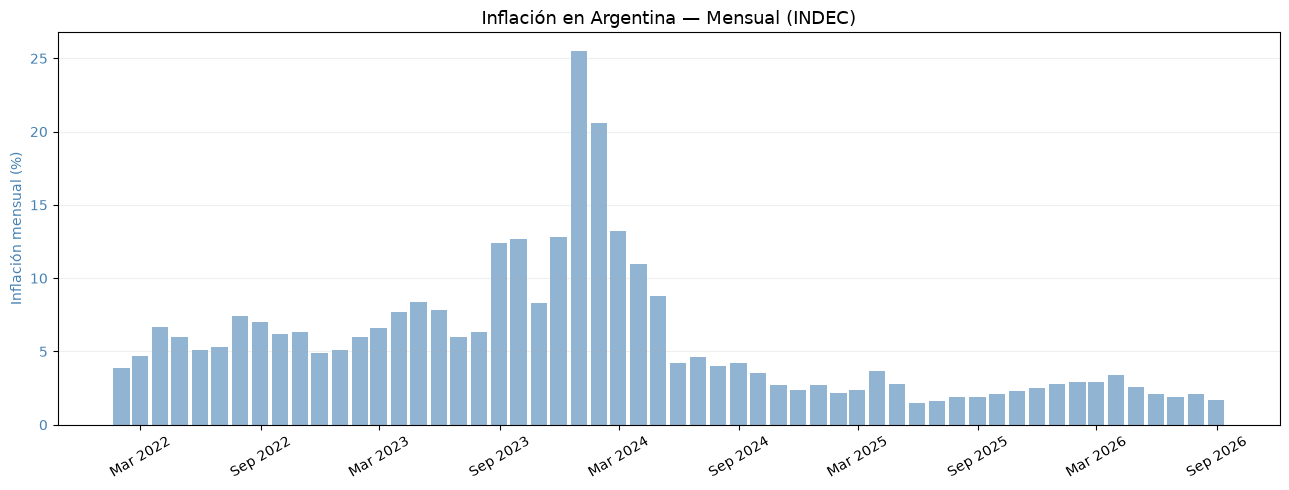

In [25]:
# Filtrar últimos 3 años para mayor legibilidad
df_plot = df_inf[df_inf['fecha'] >= '2022-01-01'].copy()

fig, ax1 = plt.subplots(figsize=(13, 5))

# Barras: inflación mensual
ax1.bar(df_plot['fecha'], df_plot['valor'], width=25, color='steelblue', alpha=0.6, label='Mensual (%)')
ax1.set_ylabel('Inflación mensual (%)', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax1.set_title('Inflación en Argentina — Mensual (INDEC)', fontsize=13)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.xticks(rotation=30)
ax1.grid(axis='y', alpha=0.2)

# Leyenda unificada
lines1, labels1 = ax1.get_legend_handles_labels()

plt.tight_layout()
plt.show()

#### 2.2 Feriados nacionales — path parameter dinámico

El endpoint de feriados recibe el año como **path parameter**.  
Esto ilustra cómo las APIs REST usan la URL para parametrizar las consultas.

In [26]:
anio = 2026
url  = f'https://api.argentinadatos.com/v1/feriados/{anio}'

resp = requests.get(url, timeout=10)
resp.raise_for_status()

df_feriados = pd.DataFrame(resp.json())
df_feriados['fecha'] = pd.to_datetime(df_feriados['fecha'])

print(f"Feriados en {anio}: {len(df_feriados)}")
print()
df_feriados[['fecha', 'tipo', 'nombre']]

Feriados en 2026: 20



,fecha,tipo,nombre
0,2026-01-01,inamovible,Año nuevo
1,2026-02-16,inamovible,Carnaval
2,2026-02-17,inamovible,Carnaval
3,2026-03-23,puente,Puente turístico no laborable
4,2026-03-24,inamovible,Día Nacional de la Memoria por la Verdad y la ...
5,2026-04-02,inamovible,Día del Veterano y de los Caídos en la Guerra ...
6,2026-04-03,inamovible,Viernes Santo
7,2026-05-01,inamovible,Día del Trabajador
8,2026-05-25,inamovible,Día de la Revolución de Mayo
9,2026-06-15,trasladable,Paso a la Inmortalidad del General Martín Güem...


In [27]:
anio = 2026
url  = f'https://api.argentinadatos.com/v1/feriados/{anio}'

try:
    resp = requests.get(url, timeout=10)
    resp.raise_for_status()

    df_feriados = pd.DataFrame(resp.json())
    df_feriados['fecha'] = pd.to_datetime(df_feriados['fecha'])

    print(f"Feriados en {anio}: {len(df_feriados)}")
    print()
    display(df_feriados[['fecha', 'tipo', 'nombre']])

except requests.exceptions.Timeout:
    print(f"Timeout: la API no respondió en 10 segundos.")
except requests.exceptions.HTTPError as e:
    print(f"Error HTTP {resp.status_code}: {e}")
except requests.exceptions.ConnectionError:
    print("Sin conexión: no se pudo alcanzar el servidor.")

Feriados en 2026: 20



,fecha,tipo,nombre
0,2026-01-01,inamovible,Año nuevo
1,2026-02-16,inamovible,Carnaval
2,2026-02-17,inamovible,Carnaval
3,2026-03-23,puente,Puente turístico no laborable
4,2026-03-24,inamovible,Día Nacional de la Memoria por la Verdad y la ...
5,2026-04-02,inamovible,Día del Veterano y de los Caídos en la Guerra ...
6,2026-04-03,inamovible,Viernes Santo
7,2026-05-01,inamovible,Día del Trabajador
8,2026-05-25,inamovible,Día de la Revolución de Mayo
9,2026-06-15,trasladable,Paso a la Inmortalidad del General Martín Güem...
